In [1]:
from unbiased_mcmc import *

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [2]:
import numpy as np 
def log_target0(x):
    return -0.5 * np.sum(x**2, axis=-1)

def log_target1(x, D):
    return -0.5 * np.sum((x - D)**2, axis=-1)


def g_log_target(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def g_grad_log_target(x, D):
    return log_target1(x, D) - log_target0(x)

In [3]:
L = 10  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [4]:

d = 2
Sigma = np.eye(d) # covaraince of the proposal of RWMH
mean_init = np.array([-2.0] * d) # mean for the initial distribution of MH
Sigma_init = np.eye(d) # covariance of the initial ditribution of MH
cholesky_Sigma = cholesky(Sigma)
inv_cholesky_Sigma = inv_cholesky(Sigma)


alpha = 3 #  scale 
D = alpha * np.array([1.0] * d)  # mean shift of the target distribution

log_target_path = lambda x, path: g_log_target(x, path, D)
grad_log_target_path = lambda x, path: g_grad_log_target(x, D)

In [5]:
mk_grid = tune_km_grid(
    lambda_grid,
    mean_init,
    Sigma_init,
    Sigma,
    cholesky_Sigma,
    inv_cholesky_Sigma,
    log_target_path,
    lag=1,
    nrep=1000,
)

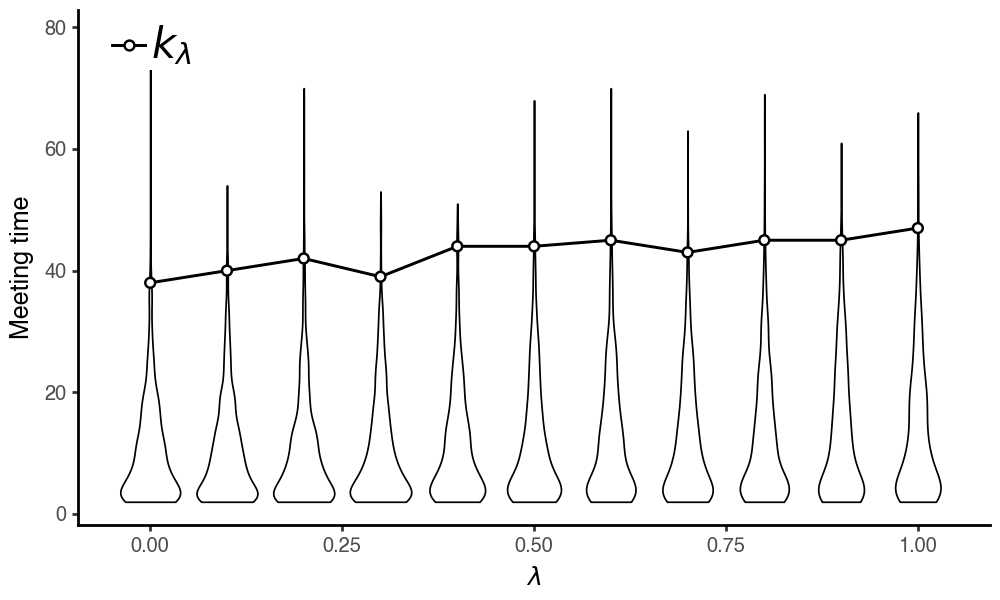

In [6]:
plot_km_grid(mk_grid, lambda_grid)

In [7]:
k_grid = mk_grid["k_grid"]
m_grid = mk_grid["m_grid"]
lag = k_grid

In [8]:
moment_results = estimate_moments(
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=1000,
    )

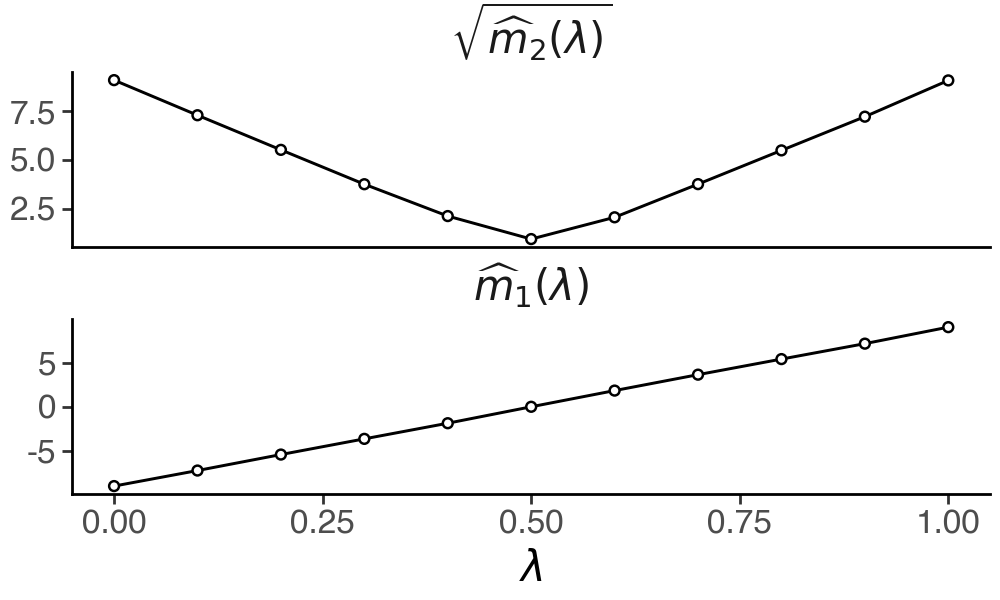

In [9]:
plot_m1_m2(moment_results, lambda_grid)

In [10]:
m2 = moment_results["m2"] # to define the optimal proposal for UPS

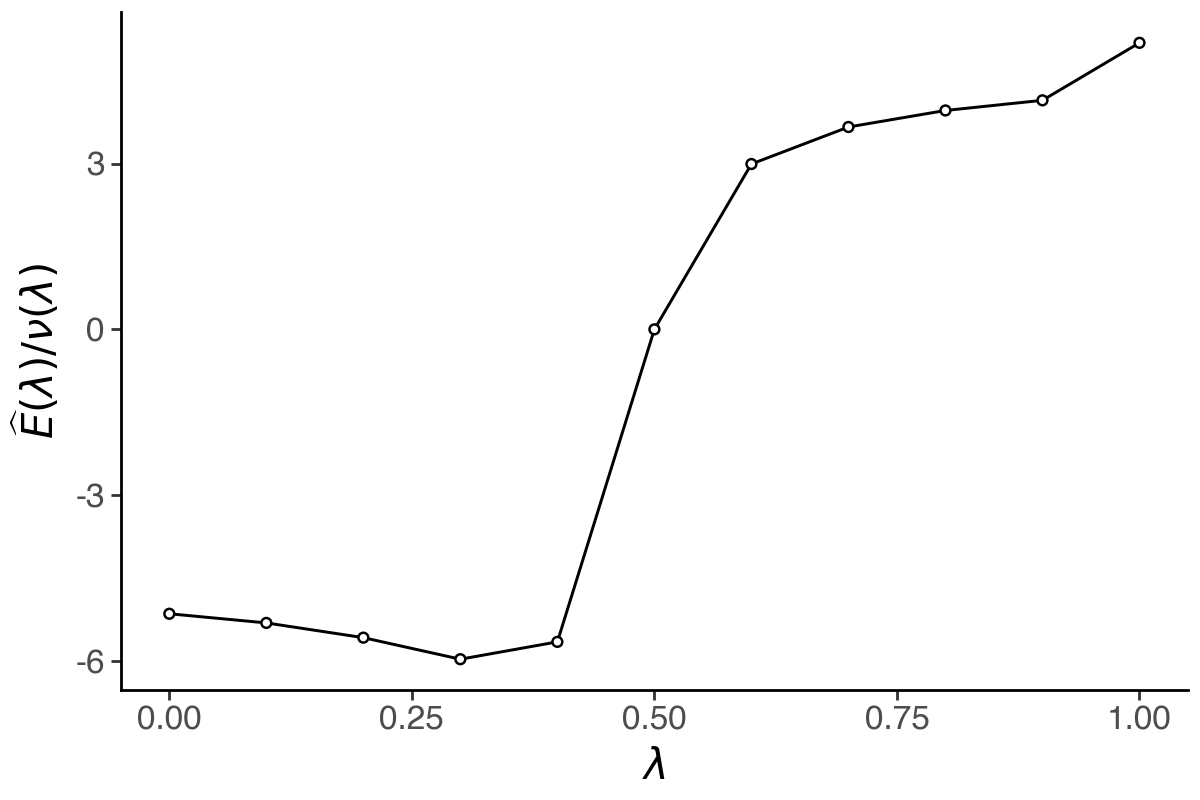

In [19]:
plot_E_lambda_over_q(
	lambda_grid,
	m2,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	nrep=1000,
)

In [11]:
N_pilot = 1000
sigma = estimate_sigma(lambda_grid, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_Sigma, inv_cholesky_Sigma, log_target_path, grad_log_target_path, N_pilot)

IS replications: 100%|██████████| 500/500 [00:00<00:00, 1804.74it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


Workers=14 | M_IS=27772 | coût moyen UPS=27773.8 | coût moyen SUPS=27771.0
MSE: {'UPS': np.float64(0.20276295354207882), 'SUPS': np.float64(0.010892602852288236), 'IS': np.float64(0.559779859682322)}


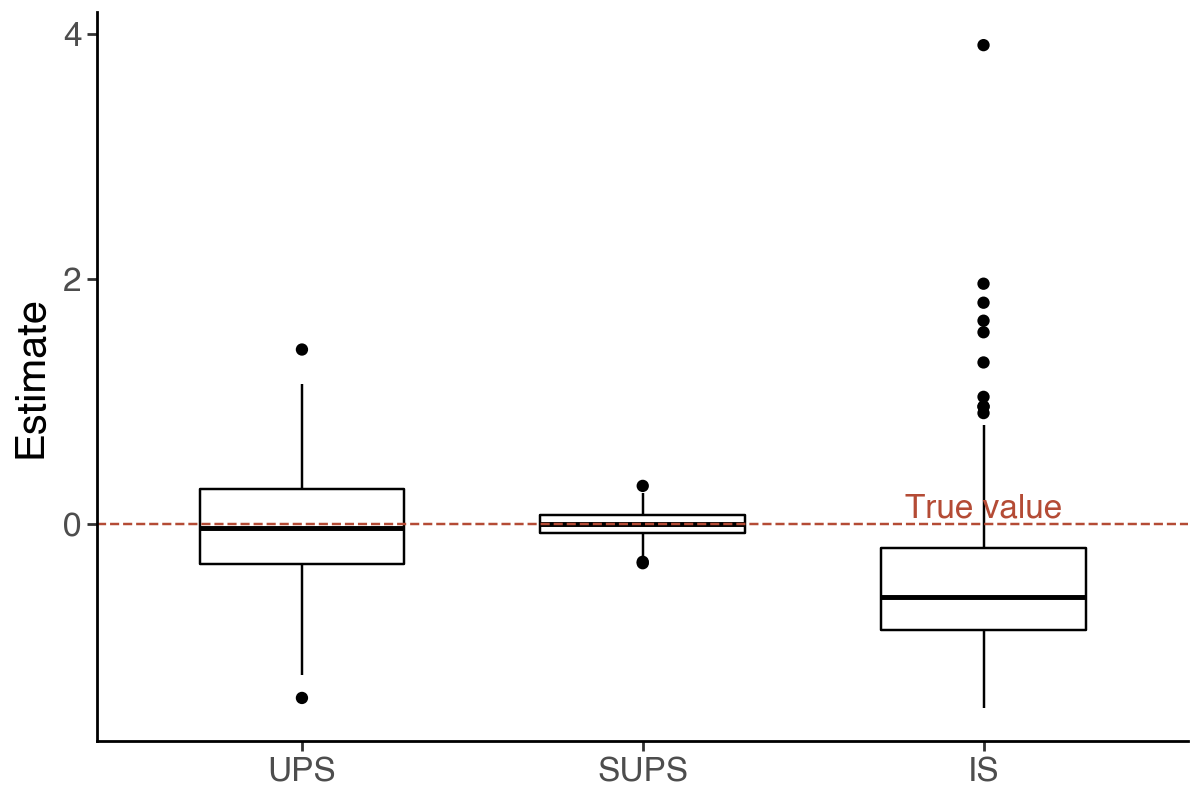

{'UPS_values': array([ 5.60173693e-01,  1.96893214e-01, -7.49777232e-02, -7.08522873e-02,
        -2.98252434e-01,  2.26499910e-01, -4.58752350e-01,  3.44629571e-01,
        -5.89430155e-01, -2.34331089e-01,  2.85507817e-01,  3.88010980e-01,
         1.25285372e-01, -4.93807410e-01,  5.15601526e-01, -3.88662479e-01,
         4.85120735e-01, -3.42265669e-01,  1.63417703e-01, -3.12191660e-01,
         4.06448683e-01,  7.66650971e-01,  1.38771957e-01,  1.21238424e-01,
        -4.84879394e-01, -8.99577211e-01, -2.09505520e-01, -8.25450771e-01,
        -2.30853653e-01, -3.04224186e-01,  5.58125797e-01, -2.91188398e-02,
         3.87832404e-01, -3.12420554e-01,  3.95017959e-01, -6.77455565e-01,
         6.33542874e-01,  6.42083399e-01, -5.63510783e-02,  5.14995827e-01,
        -2.46702577e-01, -2.04635321e-01,  2.61579740e-01,  4.07350571e-01,
        -8.68105890e-01, -6.41580011e-01, -3.70737185e-01, -4.23680775e-01,
         5.58603374e-01, -3.06666896e-01,  3.41876758e-03, -8.70707392e-02

In [ ]:
compare_estimators(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
    D,
	d,
	M=100,
	nrep=500,
	true_value=0.0,
	n_workers=14,
)

IS prefixes (max M=505645): 100%|██████████| 200/200 [00:01<00:00, 100.96it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


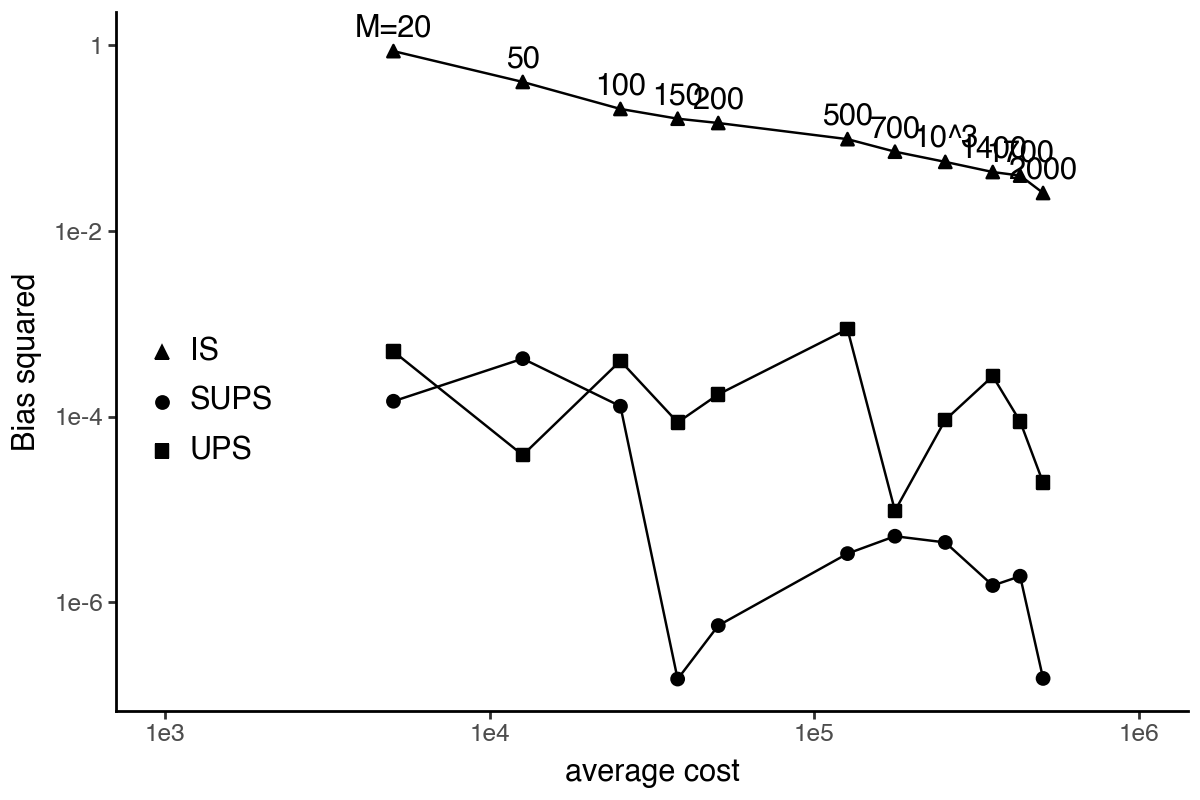

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


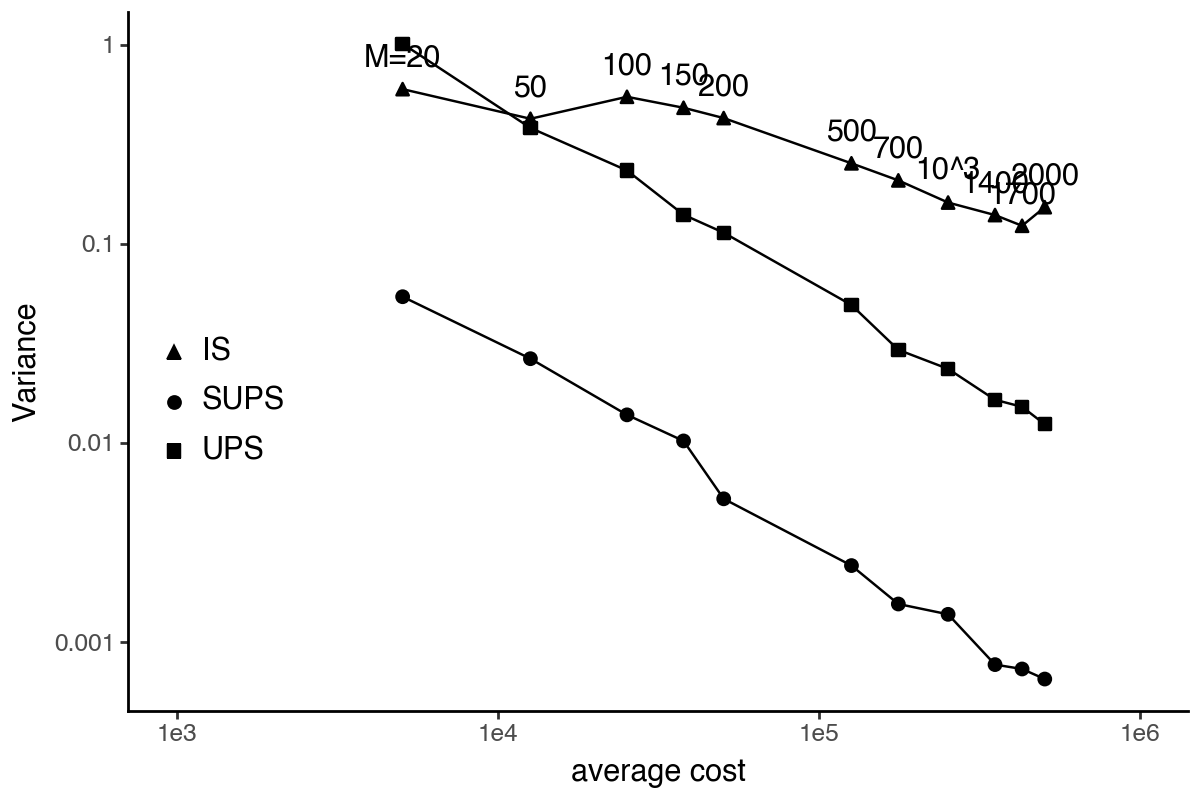

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


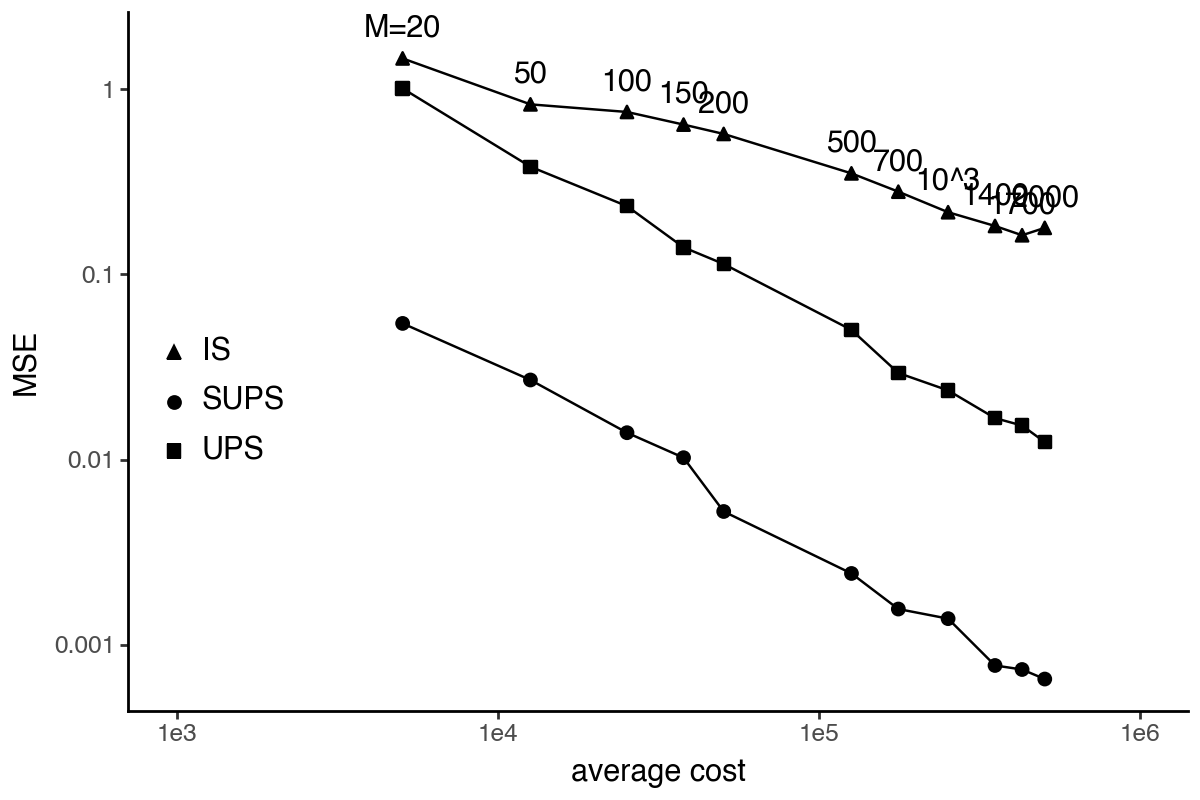

{'data':        M Estimator        Cost  Bias squared  Variance       MSE    M_is
 0     20       UPS    5055.360  5.040113e-04  1.009599  1.010103    5057
 1     20      SUPS    5058.065  1.464157e-04  0.054202  0.054349    5057
 2     20        IS    5057.000  8.696473e-01  0.597476  1.467124    5057
 3     50       UPS   12649.075  3.848448e-05  0.381533  0.381572   12648
 4     50      SUPS   12647.500  4.214403e-04  0.026474  0.026895   12648
 5     50        IS   12648.000  4.044645e-01  0.424135  0.828600   12648
 6    100       UPS   25266.760  3.991178e-04  0.233412  0.233811   25273
 7    100      SUPS   25278.285  1.293306e-04  0.013830  0.013960   25273
 8    100        IS   25273.000  2.069923e-01  0.546855  0.753848   25273
 9    150       UPS   37929.400  8.663541e-05  0.139862  0.139949   37923
 10   150      SUPS   37917.260  1.484716e-07  0.010230  0.010230   37923
 11   150        IS   37923.000  1.625447e-01  0.481764  0.644309   37923
 12   200       UPS   50563.68

In [12]:
import importlib

normal_plots = importlib.import_module("unbiased_mcmc.normal_plots")
normal_plots = importlib.reload(normal_plots)
compare_estimators_mse_by_budget = normal_plots.compare_estimators_mse_by_budget

compare_estimators_mse_by_budget(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
	D,
	d,
	M_values=tuple(np.geomspace(20, 2000, 10).round().astype(int)),
	nrep=200,
	true_value=0.0,
	n_workers=14,
)